In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder

In [2]:
df = pd.read_csv('/content/data_core.csv')

df.head()

,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name
0,26.0,52.0,38.0,Sandy,Maize,37,0,0,Urea
1,29.0,52.0,45.0,Loamy,Sugarcane,12,0,36,DAP
2,34.0,65.0,62.0,Black,Cotton,7,9,30,14-35-14
3,32.0,62.0,34.0,Red,Tobacco,22,0,20,28-28
4,28.0,54.0,46.0,Clayey,Paddy,35,0,0,Urea


In [3]:
df[['Soil Type', 'Crop Type']].dtypes

,0
Soil Type,object
Crop Type,object


In [4]:
print("Soil Types:")
print(df['Soil Type'].unique())

print("\nCrop Types:")
print(df['Crop Type'].unique())

Soil Types:
['Sandy' 'Loamy' 'Black' 'Red' 'Clayey']

Crop Types:
['Maize' 'Sugarcane' 'Cotton' 'Tobacco' 'Paddy' 'Barley' 'Wheat' 'Millets'
 'Oil seeds' 'Pulses' 'Ground Nuts']


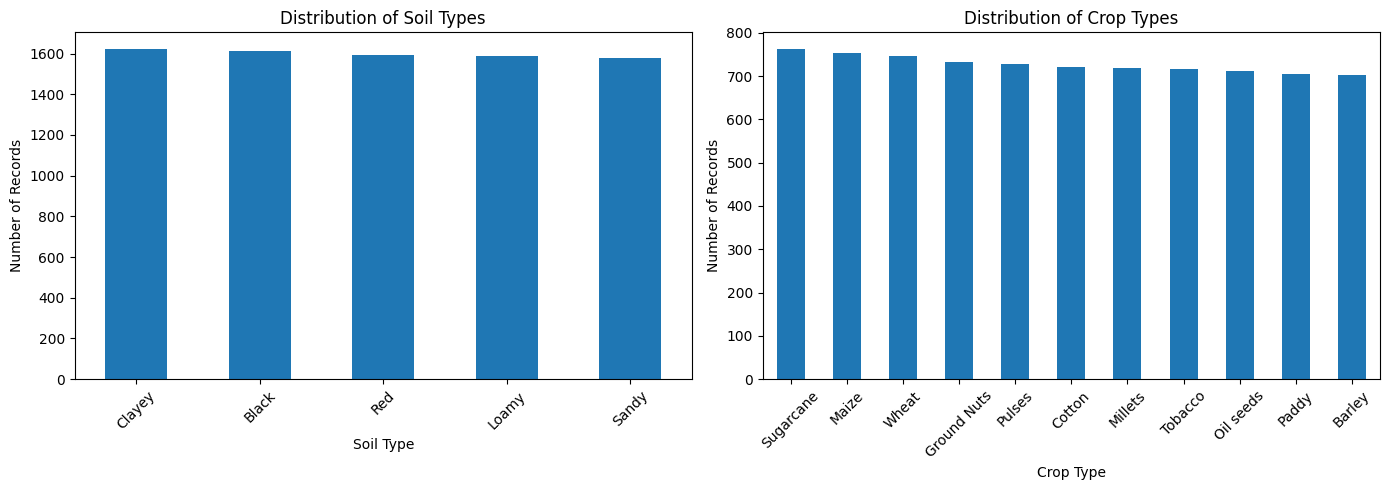

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df['Soil Type'].value_counts().plot(
    kind='bar',
    ax=axes[0]
)
axes[0].set_title('Distribution of Soil Types')
axes[0].set_xlabel('Soil Type')
axes[0].set_ylabel('Number of Records')
axes[0].tick_params(axis='x', rotation=45)

df['Crop Type'].value_counts().plot(
    kind='bar',
    ax=axes[1]
)
axes[1].set_title('Distribution of Crop Types')
axes[1].set_xlabel('Crop Type')
axes[1].set_ylabel('Number of Records')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [6]:
print("Soil Type Counts:")
print(df['Soil Type'].value_counts())

print("\nCrop Type Counts:")
print(df['Crop Type'].value_counts())

Soil Type Counts:
Soil Type
Clayey    1623
Black     1613
Red       1594
Loamy     1590
Sandy     1580
Name: count, dtype: int64

Crop Type Counts:
Crop Type
Sugarcane      763
Maize          753
Wheat          747
Ground Nuts    732
Pulses         728
Cotton         722
Millets        718
Tobacco        717
Oil seeds      711
Paddy          706
Barley         703
Name: count, dtype: int64


In [7]:
encoded_df = pd.get_dummies(
    df,
    columns=['Soil Type', 'Crop Type'],
    dtype=int
)

encoded_df.head()

,Temparature,Humidity,Moisture,Nitrogen,Potassium,Phosphorous,Fertilizer Name,Soil Type_Black,Soil Type_Clayey,Soil Type_Loamy,...,Crop Type_Cotton,Crop Type_Ground Nuts,Crop Type_Maize,Crop Type_Millets,Crop Type_Oil seeds,Crop Type_Paddy,Crop Type_Pulses,Crop Type_Sugarcane,Crop Type_Tobacco,Crop Type_Wheat
0,26.0,52.0,38.0,37,0,0,Urea,0,0,0,...,0,0,1,0,0,0,0,0,0,0
1,29.0,52.0,45.0,12,0,36,DAP,0,0,1,...,0,0,0,0,0,0,0,1,0,0
2,34.0,65.0,62.0,7,9,30,14-35-14,1,0,0,...,1,0,0,0,0,0,0,0,0,0
3,32.0,62.0,34.0,22,0,20,28-28,0,0,0,...,0,0,0,0,0,0,0,0,1,0
4,28.0,54.0,46.0,35,0,0,Urea,0,1,0,...,0,0,0,0,0,1,0,0,0,0


In [8]:
print("Original dataset shape:", df.shape)
print("Encoded dataset shape:", encoded_df.shape)

encoded_df.dtypes

Original dataset shape: (8000, 9)
Encoded dataset shape: (8000, 23)


,0
Temparature,float64
Humidity,float64
Moisture,float64
Nitrogen,int64
Potassium,int64
Phosphorous,int64
Fertilizer Name,object
Soil Type_Black,int64
Soil Type_Clayey,int64
Soil Type_Loamy,int64
